# Trading de energía con aprendizaje automático

Predecir el precio del gas a un día, convertir la predicción en posiciones y
comprobar si eso gana dinero después de costes.

El notebook está escrito para leerse de arriba abajo. Tiene dos conclusiones que
no son las que uno espera, y las dos están medidas, no afirmadas:

1. **La señal no está en el historial de precios**, está en las previsiones
   meteorológicas publicadas. Y eso es lo que distingue al trading de energía del
   de renta variable.
2. **El modelo con el mejor error de predicción es el que pierde dinero.** El
   orden de los modelos se invierte al pasar del RMSE al P&L.

Sobre los datos: aquí no hay acceso a los mercados reales, así que se trabaja con
un escenario simulado. No es un paseo aleatorio: tiene reversión a la media,
estacionalidad, saltos al alza y sensibilidad real a la temperatura, de modo que
hay señal que encontrar. Con datos reales el ejercicio es el mismo y los números
serán peores.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
from scipy import stats

from icm import graficos
from icm.energia import (
    PLANTAS, margen_planta, simular_energia, spark_spread, spark_spread_limpio,
    valor_opcionalidad, horas_en_dinero, perfil_estacional, contraste_estacionalidad,
)
from icm.ml import (
    MODELOS, ParticionWalkForward, comparar_estrategias, comparar_modelos,
    comprobar_ausencia_de_fuga, construir_matriz, coste_de_equilibrio,
    curva_beneficio, ejecutar_estrategia, importancia_variables, crear_modelo,
    resumen_estrategia, tabla_evaluacion, validacion_walk_forward,
)
from icm.ml import graficos as gml

graficos.aplicar_estilo()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 150)

## 1. El mercado

Ocho activos del complejo energético: crudo (WTI, Brent), gas (Henry Hub, TTF,
MIBGAS), electricidad (OMIE) y dos ETF sectoriales. Junto a ellos, las variables
físicas que mueven el precio.

Una nota sobre los datos reales: TTF, MIBGAS y OMIE **no cotizan en Yahoo
Finance**. Si quieres trabajar con ellos tendrás que descargar el CSV de MIBGAS o
de ESIOS y cargarlo con `cargar_precios_fichero`, que es justo para esto.

2200 sesiones, de 2018-01-01 a 2026-06-05
activos:  WTI, BRENT, HENRY_HUB, TTF, MIBGAS, OMIE, XLE, XLU
exógenas: temperatura, hdd, cdd, viento, almacenamiento, prevision_hdd, prevision_cdd, prevision_viento


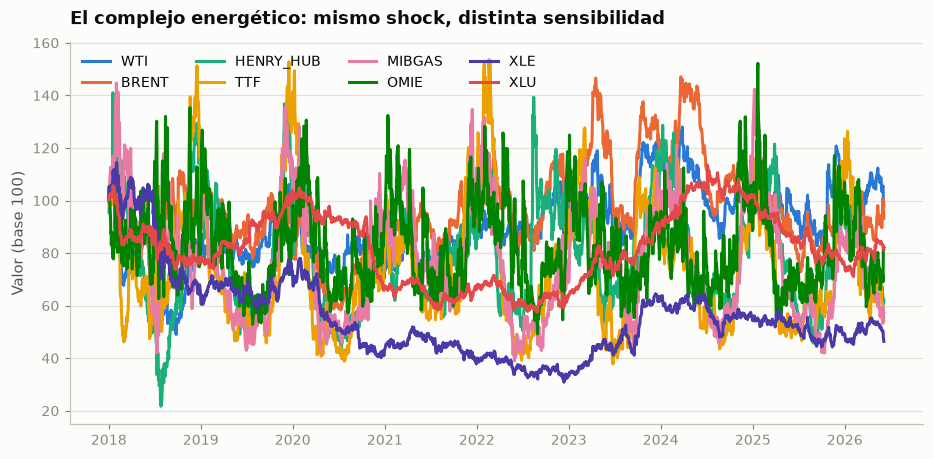

In [2]:
escenario = simular_energia(n_periodos=2200, semilla=7)
precios, exogenas = escenario.precios, escenario.exogenas

print(f"{len(precios)} sesiones, de {precios.index.min().date()} a {precios.index.max().date()}")
print(f"activos:  {', '.join(precios.columns)}")
print(f"exógenas: {', '.join(exogenas.columns)}")

base = precios / precios.iloc[0] * 100
figura, ax = graficos.series_temporales({c: base[c] for c in precios.columns},
                                        etiqueta_y="Valor (base 100)")
ax.set_title("El complejo energético: mismo shock, distinta sensibilidad");

## 2. Lo que de verdad se negocia: el spark spread

Una central de ciclo combinado no gana dinero con el precio de la luz ni con el
del gas, sino con la **diferencia** entre lo que cobra por el MWh que vende y lo
que paga por el gas que quema para producirlo.

Para generar 1 MWh eléctrico hacen falta `1/eficiencia` MWh térmicos de gas, así
que se **divide** por la eficiencia. Multiplicar es el error clásico y da un
margen absurdamente alto.

El spread *limpio* descuenta además los derechos de emisión. La diferencia entre
ambos no es cosmética: es lo que decide si la planta arranca.

Ciclo combinado de gas (referencia de mercado, 50 %): eficiencia 50%, emisión 0.2 tCO2 por MWh térmico


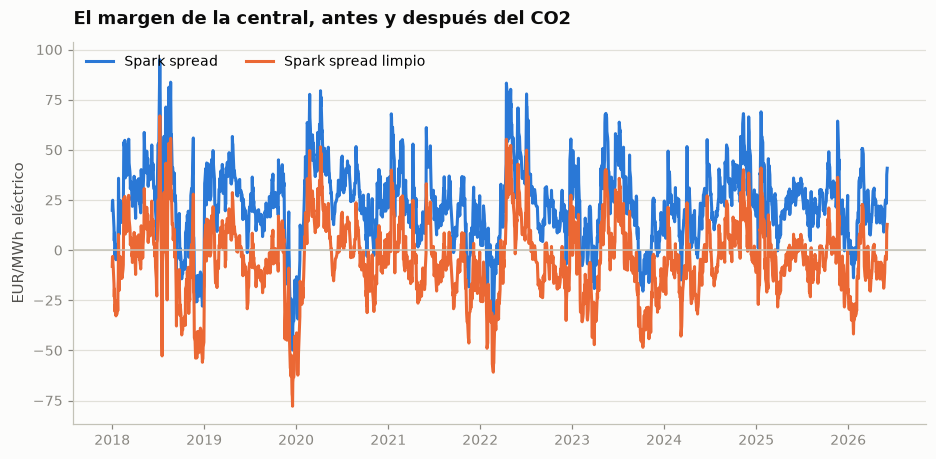

In [3]:
planta = PLANTAS["ciclo_combinado"]
print(f"{planta.nombre}: eficiencia {planta.eficiencia:.0%}, "
      f"emisión {planta.factor_emision} tCO2 por MWh térmico")

# Un precio de CO2 de escenario, en euros por tonelada.
co2 = pd.Series(70.0, index=precios.index)

sucio = spark_spread(precios["OMIE"], precios["TTF"], planta.eficiencia)
limpio = spark_spread_limpio(precios["OMIE"], precios["TTF"], co2,
                             planta.eficiencia, planta.factor_emision)

figura, ax = graficos.series_temporales(
    {"Spark spread": sucio, "Spark spread limpio": limpio},
    etiqueta_y="EUR/MWh eléctrico",
)
ax.axhline(0, color=graficos.CHROME["eje"], linewidth=1)
ax.set_title("El margen de la central, antes y después del CO2");

In [4]:
print(f"Horas en dinero sin CO2:  {horas_en_dinero(sucio):.1%}")
print(f"Horas en dinero con CO2:  {horas_en_dinero(limpio):.1%}")
print(f"\nEl coste de emisión quita {horas_en_dinero(sucio) - horas_en_dinero(limpio):.1%} "
      "de las sesiones en las que la planta sería rentable.\n")

# Una central no está obligada a producir: si el margen es negativo, para.
opcion = valor_opcionalidad(limpio)
print(f"Margen medio si produjese siempre:        {limpio.mean():7.2f} EUR/MWh")
print(f"Margen medio parando cuando pierde:       {opcion.mean():7.2f} EUR/MWh")
print(f"Valor del derecho a no producir:          {opcion.mean() - limpio.mean():7.2f} EUR/MWh")

Horas en dinero sin CO2:  89.5%
Horas en dinero con CO2:  38.3%

El coste de emisión quita 51.2% de las sesiones en las que la planta sería rentable.

Margen medio si produjese siempre:          -4.68 EUR/MWh
Margen medio parando cuando pierde:          5.07 EUR/MWh
Valor del derecho a no producir:             9.75 EUR/MWh


Ese último número es el **valor de la opcionalidad**, y es la razón por la que
valorar una central como si produjese siempre la infravalora de forma
sistemática. Es la desigualdad de Jensen: la media de `max(spread, 0)` es mayor
que `max(media del spread, 0)`.

## 3. La pregunta previa: ¿hay algo que se pueda predecir?

Antes de entrenar nada, conviene saber si existe señal. Y aquí aparece el asunto
central del notebook.

Las variables físicas afectan al precio **de forma contemporánea**: el frío de hoy
mueve el precio de hoy. Así que conocer la temperatura de hoy no dice nada sobre
el rendimiento de mañana.

In [5]:
rend_manana = np.log(precios["TTF"]).diff().shift(-1)
hdd = exogenas["hdd"]

pares = {
    "cambio de hdd de HOY vs rendimiento de HOY": (hdd.diff(), np.log(precios["TTF"]).diff()),
    "nivel de hdd de HOY vs rendimiento de MAÑANA": (hdd, rend_manana),
    "cambio de hdd de HOY vs rendimiento de MAÑANA": (hdd.diff(), rend_manana),
}
for etiqueta, (a, b) in pares.items():
    ok = a.notna() & b.notna()
    r, p = stats.pearsonr(a[ok], b[ok])
    marca = "usable" if "MAÑANA" in etiqueta else "contemporáneo, NO usable"
    print(f"  r={r:+.4f}  p={p:.1e}   {etiqueta}   [{marca}]")

  r=+0.1926  p=8.2e-20   cambio de hdd de HOY vs rendimiento de HOY   [contemporáneo, NO usable]
  r=-0.0404  p=5.8e-02   nivel de hdd de HOY vs rendimiento de MAÑANA   [usable]
  r=-0.0296  p=1.7e-01   cambio de hdd de HOY vs rendimiento de MAÑANA   [usable]


La primera correlación es fuerte pero inútil: es simultánea, no se puede operar
con ella. Las dos que sí serían usables son esencialmente cero.

**Y aquí está lo que hace distinta a la energía.** Nadie sabe el precio del gas de
mañana, pero el frío de mañana **sí se sabe hoy**: el operador del sistema y los
servicios meteorológicos publican previsiones de temperatura, demanda y
producción renovable antes de que cierre el mercado diario. Esa previsión es un
dato disponible hoy, y una mesa real la usa. No usarla no haría el análisis más
honesto: lo haría irreal.

La frontera está en la habilidad. Usar el valor futuro exacto sí sería trampa. La
previsión del escenario acierta el **cambio** con una correlación de 0,90, que es
lo que consigue una previsión meteorológica a 24 horas.

Un detalle que importa: la habilidad se mide sobre el cambio, no sobre el nivel.
Con una variable tan persistente como la temperatura, decir «mañana hará como
hoy» ya correlaciona 0,85 con lo que ocurre sin aportar nada. Solo añade valor
acertar el cambio.

In [6]:
cambio_previsto = exogenas["prevision_hdd"] - exogenas["hdd"]
cambio_real = exogenas["hdd"].shift(-1) - exogenas["hdd"]

ok = cambio_previsto.notna() & cambio_real.notna()
print(f"habilidad de la previsión (sobre el cambio): "
      f"{stats.pearsonr(cambio_previsto[ok], cambio_real[ok])[0]:.3f}")

ok = cambio_previsto.notna() & rend_manana.notna()
r, p = stats.pearsonr(cambio_previsto[ok], rend_manana[ok])
print(f"\ncambio de hdd PREVISTO vs rendimiento de MAÑANA:  r={r:+.4f}  p={p:.1e}")
print("\nAhí está la señal. No en el historial de precios, en el parte meteorológico.")

habilidad de la previsión (sobre el cambio): 0.898

cambio de hdd PREVISTO vs rendimiento de MAÑANA:  r=+0.1634  p=1.3e-14

Ahí está la señal. No en el historial de precios, en el parte meteorológico.


## 4. La matriz de variables, y la garantía de no mirar al futuro

59 variables en siete familias: retardos del propio activo, medias móviles,
volatilidad realizada, momento, calendario, retardos de los otros activos y las
exógenas con su previsión.

Lo importante no es la lista, es la garantía. `comprobar_ausencia_de_fuga`
reconstruye la matriz alterando los datos posteriores a una fecha y comprueba que
ninguna variable de esa fecha cambia. Si cambia, hay fuga y lanza un error
diciendo qué columna y en qué fecha.

Es una garantía **comprobable**, no una promesa en un comentario.

In [7]:
md_datos = construir_matriz(precios, "TTF", horizonte=1, exogenas=exogenas)
print(f"X: {md_datos.X.shape}   y: {md_datos.y.shape}\n")
for familia, columnas in md_datos.nombres_grupo.items():
    print(f"  {familia:<14} {len(columnas):>3} variables   {', '.join(columnas[:3])}...")

comprobar_ausencia_de_fuga(construir_matriz, precios, "TTF", exogenas=exogenas)
print("\nAuditoría de fuga: PASA")

X: (2136, 59)   y: (2136,)

  retardos         5 variables   rend_ret1, rend_ret2, rend_ret3...
  medias           3 variables   precio_mm5_rel, precio_mm10_rel, precio_mm21_rel...
  volatilidad      3 variables   rend_vol5, rend_vol21, rend_vol63...
  momento          3 variables   rend_mom5, rend_mom21, rend_mom63...
  calendario       8 variables   dia_martes, dia_miercoles, dia_jueves...
  cruzadas        21 variables   cruz_WTI_ret1, cruz_WTI_ret2, cruz_WTI_ret5...
  exogenas        16 variables   exo_temperatura_ret0, exo_temperatura_ret1, exo_hdd_ret0...

Auditoría de fuga: PASA


In [8]:
# Y para que la garantía signifique algo, hay que ver que detecta una fuga real.
from icm.comun import ErrorDatos
from icm.ml.caracteristicas import MatrizDatos, objetivo_rendimiento_futuro

def constructor_tramposo(precios, objetivo, **kwargs):
    """Mete el precio de mañana como variable. Es la trampa más burda posible."""
    base = construir_matriz(precios, objetivo, **kwargs)
    X = base.X.copy()
    X["trampa"] = precios[objetivo].shift(-1).reindex(X.index)
    grupos = dict(base.nombres_grupo, trampa=["trampa"])
    return MatrizDatos(X=X.dropna(), y=base.y.reindex(X.dropna().index), nombres_grupo=grupos)

try:
    comprobar_ausencia_de_fuga(constructor_tramposo, precios, "TTF", exogenas=exogenas)
    print("PROBLEMA: la auditoría no ha detectado la fuga")
except ErrorDatos as e:
    print("Auditoría sobre un constructor con fuga deliberada:")
    print(f"  ErrorDatos: {str(e)[:200]}")

Auditoría sobre un constructor con fuga deliberada:
  ErrorDatos: Fuga de informacion del futuro en la variable 'trampa': en la fecha 2022-03-21 vale 41.7265 con la serie completa y 52.0975 al reescribir lo posterior a 2022-03-21. Una variable de esa fecha no puede 


## 5. Partir la serie sin hacer trampas

La validación cruzada al azar es el error más destructivo del ML financiero:
mezcla pasado y futuro, entrena con lo que quiere predecir y da resultados
espectaculares e irreproducibles.

Aquí las particiones van **hacia delante**, con un margen (*embargo*) entre
entrenamiento y prueba: con un objetivo a un día, la última observación del
entrenamiento se solapa con el periodo de prueba y filtraría información.

El gráfico vale más que cualquier afirmación: se ve que el entrenamiento siempre
precede a la prueba y que no hay solape.

inicio_entrenamiento fin_entrenamiento  n_entrenamiento  embargo inicio_prueba fin_prueba  n_prueba
          2018-03-29        2018-08-15              100        1    2018-08-17 2020-03-09       407
          2018-03-29        2020-03-06              507        1    2020-03-10 2021-09-29       407
          2018-03-29        2021-09-28              914        1    2021-09-30 2023-04-21       407
          2018-03-29        2023-04-20             1321        1    2023-04-24 2024-11-12       407
          2018-03-29        2024-11-11             1728        1    2024-11-13 2026-06-04       407


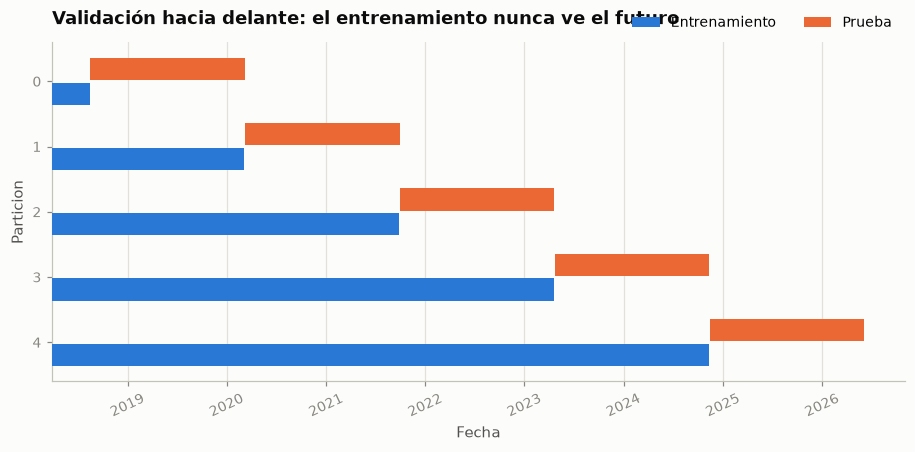

In [9]:
particion = ParticionWalkForward(n_particiones=5, embargo=1)
descripcion = particion.describir(md_datos.X)
print(descripcion.to_string(index=False))

figura, ax = gml.particiones_walk_forward(descripcion)
ax.set_title("Validación hacia delante: el entrenamiento nunca ve el futuro");

## 6. Los modelos

Cinco candidatos, y el primero es el que importa:

- **`media_cero`** predice siempre cero. Es la referencia honesta: sobre
  rendimientos, el paseo aleatorio dice que el mejor pronóstico es cero. Cualquier
  modelo tiene que batirla, y casi ninguno lo hace.
- **ridge** y **lasso**, regresión regularizada.
- **árbol potenciado**, que es lo que suele ganar con datos tabulares.

La tabla incluye el **contraste de Diebold-Mariano** frente a la referencia. Sin
él, «mi modelo tiene 0,02 menos de RMSE» no significa nada, porque la diferencia
puede estar dentro del ruido muestral.

In [10]:
NOMBRES = ["media_cero", "ridge", "lasso", "arbol_potenciado"]
tabla, predicciones = comparar_modelos(md_datos.X, md_datos.y, NOMBRES, particion)
tabla.round(4)

,mae,rmse,mase,acierto_direccional,ic,p_valor_dm,n_observaciones
modelo,,,,,,,
media_cero,0.0374,0.0494,1.0000,NaN,NaN,1.0,2035
arbol_potenciado,0.0429,0.0562,1.1472,0.5125,0.0256,0.0,2035
ridge,0.0881,0.1649,2.3550,0.5327,0.0854,0.0,2035
lasso,0.1534,0.3273,4.1011,0.5337,0.0881,0.0,2035


Ninguno bate a `media_cero`: todos tienen **MASE mayor que 1**, y el p-valor de
Diebold-Mariano dice que la diferencia es significativa. Es decir, son
significativamente *peores* en error cuadrático.

Y sin embargo, mira las otras dos columnas: la correlación de información es
positiva y el acierto direccional está por encima del 50 %. Los modelos **sí**
capturan señal.

No es una contradicción. Es álgebra:

$$\text{MSE}(\hat y) = \text{MSE}(0) - 2\,\text{cov}(\hat y, y) + \text{var}(\hat y)$$

Para batir al cero hace falta que la covarianza compense la varianza de la propia
predicción. Un modelo que acierta la dirección pero exagera la magnitud pierde en
MSE mientras acumula aciertos. Y para operar, lo que cuenta es la dirección.

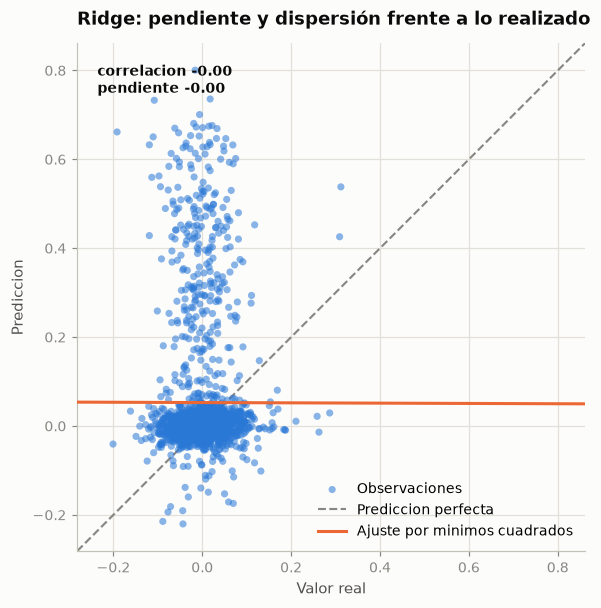

In [11]:
pred_ridge = predicciones["ridge"].dropna()
figura, ax = gml.dispersion_prediccion(md_datos.y.reindex(pred_ridge.index), pred_ridge)
ax.set_title("Ridge: pendiente y dispersión frente a lo realizado");

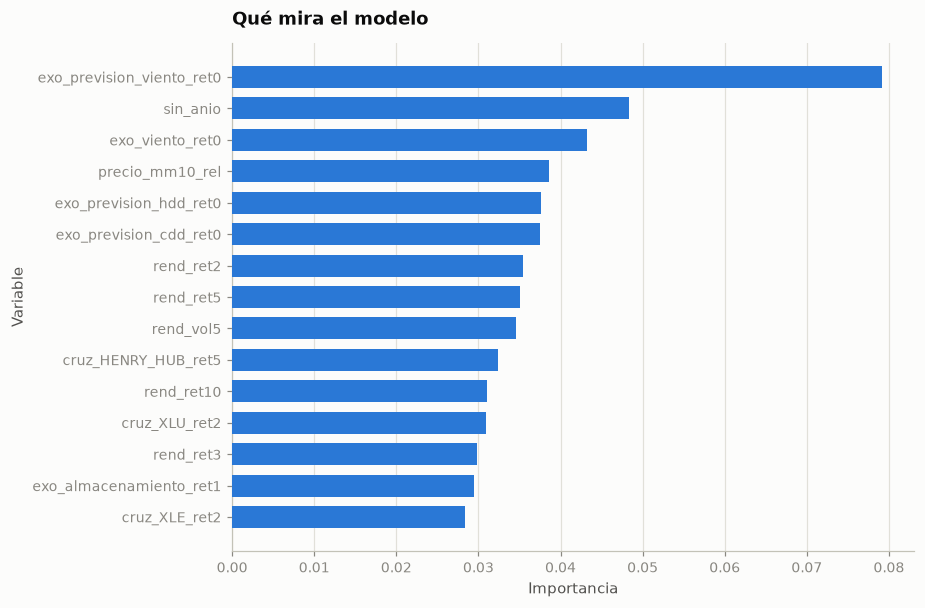

In [12]:
modelo = crear_modelo("arbol_potenciado")
importancia = importancia_variables(modelo, md_datos.X, md_datos.y, n_repeticiones=5)
figura, ax = gml.importancia_variables(importancia, n=15)
ax.set_title("Qué mira el modelo");

## 7. Una red neuronal

Una LSTM sobre ventanas de 20 sesiones, dentro de la misma validación hacia
delante. Configuración deliberadamente pequeña: con 1.700 observaciones y 59
variables, una red grande memoriza.

Es la parte más vistosa de un trabajo y casi nunca la que gana. Veamos.

In [13]:
from icm.ml.redes import RedSecuencial, torch_disponible

if not torch_disponible():
    print("PyTorch no está instalado. Instálalo con:")
    print("  pip install torch --index-url https://download.pytorch.org/whl/cpu")
else:
    red = RedSecuencial(arquitectura="lstm", ventana=20, unidades=24, capas=1,
                        epocas=40, paciencia=6, semilla=42)
    resultado_red = validacion_walk_forward(red, md_datos.X, md_datos.y, particion)
    predicciones["lstm"] = resultado_red.predicciones
    print(f"LSTM validada sobre {len(resultado_red.predicciones)} observaciones "
          f"fuera de muestra, en {len(resultado_red.modelos)} particiones")

LSTM validada sobre 2035 observaciones fuera de muestra, en 5 particiones


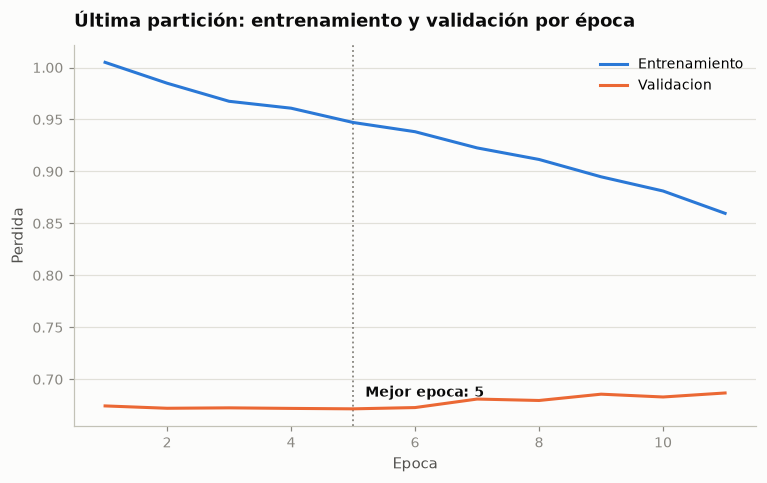

In [14]:
if torch_disponible():
    historial = resultado_red.modelos[-1].historial
    figura, ax = gml.historial_entrenamiento(historial)
    ax.set_title("Última partición: entrenamiento y validación por época");

### Un paso de alineación, que no es burocracia

Las predicciones son **fuera de muestra**: sólo existen para las fechas que cayeron
en algún tramo de prueba, y la LSTM además pierde las primeras sesiones de cada
tramo porque necesita una ventana de historia. Así que hay menos predicciones que
observaciones.

Comparar series de longitudes distintas emparejaría fechas que no se corresponden,
y por eso la librería se niega a hacerlo en lugar de recortar por su cuenta. El
recorte lo decide quien analiza, no la función.

In [15]:
indice = md_datos.y.index
for pred in predicciones.values():
    indice = indice.intersection(pred.dropna().index)

objetivo = md_datos.y.reindex(indice)
objetivo.attrs.update(md_datos.y.attrs)   # la convención de fechas viaja con la serie
predicciones = {n: p.reindex(indice) for n, p in predicciones.items()}

print(f"{len(md_datos.y)} observaciones en total, {len(indice)} con predicción de "
      f"los {len(predicciones)} modelos")
print(f"tramo evaluado: {indice.min().date()} a {indice.max().date()}")

2136 observaciones en total, 1940 con predicción de los 5 modelos
tramo evaluado: 2018-09-13 a 2026-06-04


In [16]:
tabla_completa = tabla_evaluacion(objetivo, predicciones)
tabla_completa.round(4)

,mae,rmse,mase,acierto_direccional,ic,p_valor_dm,n_observaciones
modelo,,,,,,,
media_cero,0.0372,0.0492,1.0000,NaN,NaN,1.0,1939
ingenua,0.0372,0.0492,1.0000,NaN,NaN,1.0,1939
lstm,0.0387,0.0509,1.0412,0.5333,0.0482,0.0,1939
arbol_potenciado,0.0425,0.0558,1.1427,0.5142,0.0294,0.0,1939
ridge,0.0897,0.1681,2.4096,0.5343,0.0898,0.0,1939
lasso,0.1582,0.3348,4.2512,0.5353,0.0917,0.0,1939


## 8. Del error al dinero

Aquí es donde el análisis cambia de sentido.

Cada predicción se convierte en una posición y se ejecuta contra el rendimiento
del día siguiente, con **2 puntos básicos de coste** por nominal movido. El coste
importa: una predicción diminuta no paga la horquilla.

Un detalle de implementación que merece una línea, porque es el fallo más
frecuente de los backtests: la serie objetivo ya viene adelantada (su valor en *t*
es el rendimiento de *t* a *t+1*), así que aplicarle además un retardo la
desplazaría dos veces. La librería lo detecta por la marca que la serie lleva
consigo y se niega a hacerlo. Medido sobre estos datos, el doble desplazamiento
convertía un Sharpe de +2,6 en −0,5 sin dar ningún aviso.

In [17]:
estrategias = {
    nombre: ejecutar_estrategia(pred, objetivo, coste_bps=2.0)
    for nombre, pred in predicciones.items()
    if nombre != "media_cero"
}
comparacion = comparar_estrategias(estrategias)
comparacion.round(3)

,observaciones,rentabilidad_anualizada,volatilidad_anualizada,ratio_sharpe,sharpe_bruto,merma_sharpe,maxima_caida,var_historico_95,rotacion_media,coste_total_anualizado,coste_bps
estrategia,,,,,,,,,,,
lasso,1940.0,0.868,0.779,1.114,1.197,0.083,-0.935,0.074,0.677,0.034,2.0
ridge,1940.0,0.771,0.780,0.989,1.071,0.082,-0.905,0.074,0.704,0.035,2.0
lstm,1940.0,0.546,0.780,0.699,0.732,0.033,-0.730,0.075,0.328,0.017,2.0
arbol_potenciado,1940.0,-0.089,0.782,-0.114,-0.067,0.047,-0.939,0.077,0.786,0.040,2.0


In [18]:
# El orden por error frente al orden por dinero, lado a lado.
resumen = pd.DataFrame({
    "MASE (error)": tabla_completa["mase"],
    "acierto direccional": tabla_completa["acierto_direccional"],
    "Sharpe (dinero)": comparacion["ratio_sharpe"],
}).dropna(how="all")
resumen["orden por error"] = resumen["MASE (error)"].rank()
resumen["orden por dinero"] = resumen["Sharpe (dinero)"].rank(ascending=False)
resumen.round(3)

,MASE (error),acierto direccional,Sharpe (dinero),orden por error,orden por dinero
arbol_potenciado,1.143,0.514,-0.114,4.0,4.0
ingenua,1.000,NaN,NaN,1.5,NaN
lasso,4.251,0.535,1.114,6.0,1.0
lstm,1.041,0.533,0.699,3.0,3.0
media_cero,1.000,NaN,NaN,1.5,NaN
ridge,2.410,0.534,0.989,5.0,2.0


Los dos órdenes no coinciden. Puede incluso que estén casi invertidos: el modelo
con el mejor MASE es el que peor lo hace en Sharpe.

La razón es la de antes. El árbol potenciado predice magnitudes pequeñas y
conservadoras, lo que minimiza el error cuadrático, pero su dirección es casi
aleatoria. Los lineales exageran la magnitud —y pagan por ello en MSE— pero
aciertan la dirección más a menudo, y eso es lo único que cobra una posición.

**Si eliges modelo por el RMSE, eliges el que pierde dinero.**

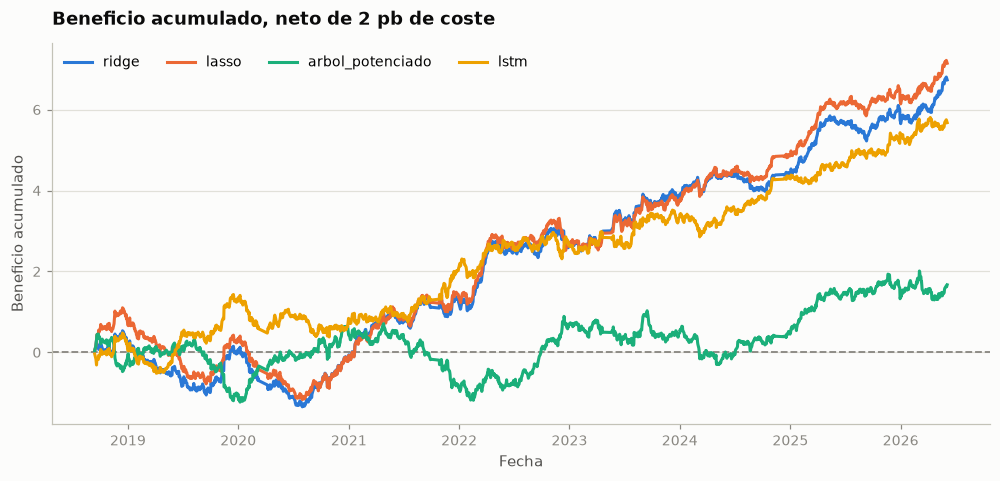

In [19]:
figura, ax = gml.curva_beneficio({n: e.pnl.cumsum() for n, e in estrategias.items()})
ax.set_title("Beneficio acumulado, neto de 2 pb de coste");

## 9. ¿Cuánta fricción aguanta?

Un Sharpe alto con 2 pb de coste no dice gran cosa si la estrategia se hunde con
5. El **coste de equilibrio** es el coste que deja el Sharpe en cero, y es la
forma honesta de presentar una estrategia: dice cuánta fricción soporta antes de
dejar de valer.

Como referencia: un futuro líquido está en 1-2 pb; un mercado de energía estrecho,
entre 20 y 50.

In [20]:
for nombre, pred in predicciones.items():
    if nombre == "media_cero":
        continue
    eq = coste_de_equilibrio(pred, objetivo)
    veredicto = "aguanta un mercado estrecho" if eq > 50 else (
        "solo un mercado líquido" if eq > 5 else "no aguanta ni el mejor mercado")
    print(f"  {nombre:<20} {eq:6.1f} pb   {veredicto}")

  ridge                  34.1 pb   solo un mercado líquido
  lasso                  38.5 pb   solo un mercado líquido
  arbol_potenciado        0.0 pb   no aguanta ni el mejor mercado
  lstm                   54.2 pb   aguanta un mercado estrecho


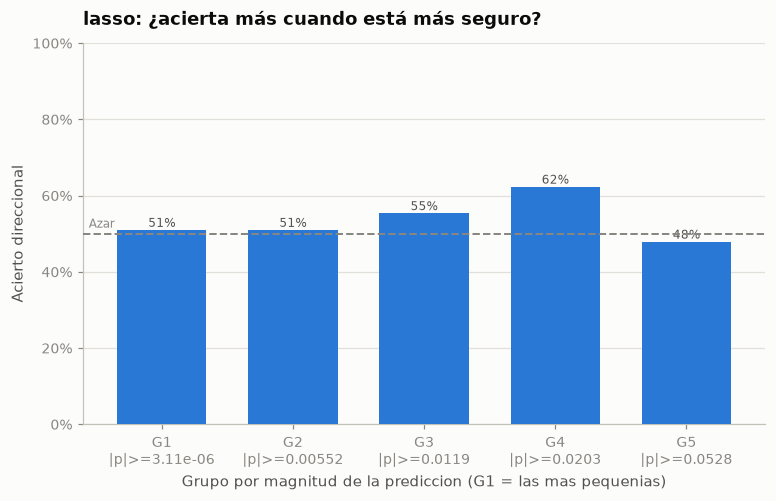

In [21]:
mejor = comparacion["ratio_sharpe"].idxmax()
figura, ax = gml.acierto_por_magnitud(objetivo, predicciones[mejor], n_grupos=5)
ax.set_title(f"{mejor}: ¿acierta más cuando está más seguro?");

Ese gráfico decide si conviene operar con umbral. Si el acierto crece con la
magnitud de la predicción, filtrar las señales pequeñas mejora la estrategia: se
opera menos y se acierta más. Si el acierto es plano, la confianza del modelo no
informa y el umbral solo ahorra costes sin aportar señal.

In [22]:
sin_umbral = ejecutar_estrategia(predicciones[mejor], objetivo, coste_bps=2.0, modo="signo")
desviacion = predicciones[mejor].std()
con_umbral = ejecutar_estrategia(predicciones[mejor], objetivo, coste_bps=2.0,
                                 modo="umbral", umbral=0.5 * desviacion)
pd.DataFrame({
    "sin umbral": resumen_estrategia(sin_umbral),
    "con umbral (0,5 sigma)": resumen_estrategia(con_umbral),
}).round(4)

,sin umbral,"con umbral (0,5 sigma)"
observaciones,1940.0000,1940.0000
rentabilidad_anualizada,0.8681,-0.0785
volatilidad_anualizada,0.7794,0.3318
ratio_sharpe,1.1138,-0.2367
sharpe_bruto,1.1971,-0.2350
merma_sharpe,0.0833,0.0016
maxima_caida,-0.9355,-0.6985
var_historico_95,0.0737,0.0244
rotacion_media,0.6773,0.0115
coste_total_anualizado,0.0341,0.0006


## 10. El riesgo de la estrategia

La cuenta de resultados de una estrategia es una serie de rendimientos como
cualquier otra, así que se le puede aplicar todo el aparato de riesgo del
paquete: VaR, Expected Shortfall, caídas desde máximos y el contraste del propio
modelo de VaR.

Esto es lo que se le pide a una mesa de verdad, y es la parte que casi nunca
aparece en un trabajo de ML: no basta con ganar, hay que saber cuánto se puede
perder mientras se gana.

In [23]:
from icm.cartera import resumen_metricas
from icm.riesgo import serie_caidas, tabla_caidas, tabla_medidas

pnl = estrategias[mejor].pnl
print(f"=== {mejor}: la estrategia como serie de rendimientos ===\n")
print(resumen_metricas(pnl).round(4).to_string())

=== lasso: la estrategia como serie de rendimientos ===

observaciones              1940.0000
rentabilidad_acumulada      121.8496
rentabilidad_anualizada       0.8681
volatilidad_anualizada        0.7794
ratio_sharpe                  1.1138
ratio_sortino                 1.6844
ratio_calmar                  0.9280
maxima_caida                 -0.9355
asimetria                     0.1977
curtosis_exceso               3.2882
var_historico_95              0.0737
es_historico_95               0.1037


In [24]:
tabla_medidas(pnl, niveles=(0.95, 0.99), valor_cartera=1_000_000).round(5)

var      es  var_monetario  es_monetario
metodo             nivel                                             
historico          0.95   0.0737  0.1037     73709.7779   103665.0847
                   0.99   0.1198  0.1544    119799.6295   154425.3296
parametrico_normal 0.95   0.0771  0.0976     77076.0103    97592.1696
                   0.99   0.1105  0.1272    110536.1930   127173.9415
parametrico_t      0.95   0.0740  0.1033     73962.5131   103258.2137
                   0.99   0.1200  0.1528    120008.7524   152822.8214
cornish_fisher     0.95   0.0710  0.1150     71022.4385   115004.8501
                   0.99   0.1404  0.1945    140419.2813   194530.3419

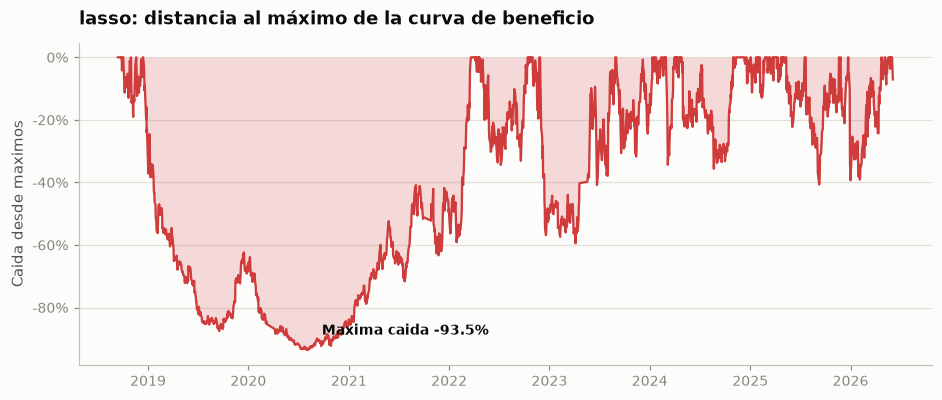

In [25]:
figura, ax = graficos.caidas(serie_caidas(pnl, tipo="simple"))
ax.set_title(f"{mejor}: distancia al máximo de la curva de beneficio");

### Y aquí hay que parar un momento

Mira esos dos números juntos: un ratio de Sharpe por encima de 1 y una **máxima
caída de más del 90 %**, con una volatilidad anualizada cercana al 80 %.

**Eso no es una estrategia invertible, es una apuesta.** Nadie mantiene una
posición que en algún momento ha perdido nueve décimas partes de lo acumulado, y
ningún comité de riesgos la aprobaría. El Sharpe alto viene de que el gas se mueve
muchísimo y la posición es de tamaño fijo: se acierta más de lo que se falla, pero
con una amplitud que ningún balance aguanta.

Presentar el Sharpe sin decir esto sería el clásico resultado de laboratorio que
se desmonta el primer día. El arreglo no es buscar otro modelo: es **dimensionar la
posición**, que es un problema distinto y se resuelve aparte.

`objetivo_volatilidad` escala la posición con la volatilidad reciente para apuntar
a un riesgo constante. Con 10 % anual objetivo, que es una cifra defendible:

Dos detalles de implementación que son la misma trampa de siempre disfrazada:

**La volatilidad con la que se dimensiona tiene que conocerse en el momento de
decidir.** Es tentador calcularla sobre la serie objetivo, pero esa serie está
adelantada: su ventana que termina en *t* incluye el rendimiento de *t* a *t+1*,
que es exactamente el que se va a operar. Hay que usar los rendimientos
contemporáneos, cuyo valor en *t* es el de ayer a hoy.

**Y la posición ya calculada hay que pasarla tal cual.** `ejecutar_estrategia`
espera una predicción y deriva la posición por su cuenta, así que para entregarle
una posición hecha se usa `modo="proporcional"` con `escala=1.0`, que es el paso
directo. Sin fijar la escala, la función la renormaliza por la desviación típica
y deshace el escalado entero sin decir nada.

In [26]:
from icm.ml import objetivo_volatilidad

# Volatilidad CONTEMPORANEA: su valor en t es el de ayer a hoy, conocido al decidir.
rend_contemporaneo = np.log(precios["TTF"]).diff()
vol = rend_contemporaneo.rolling(21).std().reindex(indice) * np.sqrt(252)

posicion = objetivo_volatilidad(np.sign(predicciones[mejor]), vol,
                                objetivo_anual=0.10, limite=3.0)

tamano_fijo = ejecutar_estrategia(predicciones[mejor], objetivo, coste_bps=2.0)
riesgo_objetivo = ejecutar_estrategia(posicion, objetivo, coste_bps=2.0,
                                      modo="proporcional", escala=1.0, limite=3.0)

filas = ["rentabilidad_anualizada", "volatilidad_anualizada", "ratio_sharpe",
         "maxima_caida", "var_historico_95", "rotacion_media"]
pd.DataFrame({
    "tamaño fijo": resumen_estrategia(tamano_fijo),
    "riesgo objetivo 10%": resumen_estrategia(riesgo_objetivo),
}).loc[filas].round(4)

,tamaño fijo,riesgo objetivo 10%
rentabilidad_anualizada,0.8681,0.1221
volatilidad_anualizada,0.7794,0.1103
ratio_sharpe,1.1138,1.1070
maxima_caida,-0.9355,-0.2723
var_historico_95,0.0737,0.0102
rotacion_media,0.6773,0.0988


Ahora sí: la volatilidad baja de casi el 80 % al 11 %, cerca del 10 % pedido, y la
caída máxima pasa de más del 90 % a alrededor del 25 %. La rentabilidad baja
también, y **debe** bajar: se está asumiendo mucho menos riesgo.

Lo interesante es el ratio de Sharpe, que **no se desploma**. Ese era el contraste:
un Sharpe que se hunde al limitar el riesgo era un Sharpe que vivía del
apalancamiento; uno que se mantiene indica que la señal es real y lo único que
sobraba era el tamaño de la apuesta.

La posición media pasa de 1 a en torno a 0,14 del nominal. Dicho de otro modo, la
versión de tamaño fijo estaba operando con siete veces el riesgo que la señal
justifica.

## 11. Qué llevarse de aquí

**1. En energía, la señal viene de las previsiones publicadas, no del historial de
precios.** Medido en la sección 3: el nivel de temperatura de hoy correlaciona
−0,03 con el rendimiento de mañana; el cambio previsto, +0,20. Un modelo
alimentado solo con precios pasados no tiene de dónde sacar nada, y esa es la
diferencia estructural con la renta variable.

**2. El error de predicción y el dinero ordenan los modelos de forma distinta, y a
veces opuesta.** La sección 8 lo pone lado a lado. Elegir por RMSE es elegir por
la métrica equivocada, y la razón es algebraica, no anecdótica: minimizar el error
cuadrático premia la prudencia en la magnitud, y una posición no cobra por la
magnitud sino por el signo.

**3. Batir a «predecir cero» es dificilísimo, y hay que medirlo con un
contraste.** Ninguno de los modelos lo consigue en MASE. Sin el contraste de
Diebold-Mariano no sabríamos si esa diferencia es real o ruido.

**4. La garantía de no mirar al futuro tiene que ser comprobable.** No basta con
tener cuidado: la sección 4 audita la matriz y demuestra, con una fuga inyectada a
propósito, que la auditoría sirve. El fallo más caro de este proyecto fue
precisamente un desfase de un periodo que no daba error ni aviso, solo un
resultado plausible y con el signo al revés.

**5. Un Sharpe sin coste de equilibrio ni caída máxima no es un resultado.** La
sección 9 dice cuánta fricción aguanta cada estrategia y la 10, cuánto se puede
perder mientras se gana. La mejor de aquí tiene Sharpe por encima de 1 y una
caída superior al 90 % antes de dimensionar: sobre el papel funciona y en la
práctica nadie la mantendría. Con la posición escalada a un 10 % de volatilidad
objetivo, la caída baja al 25 % y el Sharpe se mantiene, que es la señal de que
sobraba tamaño y no faltaba modelo. Dimensionar es un problema aparte del de
predecir, y saltárselo convierte un buen modelo en una apuesta.

---

Y una advertencia final que conviene no perder de vista: **estos datos son
simulados, y el simulador tiene la señal que yo le puse.** Que un modelo la
encuentre demuestra que el pipeline funciona, no que el método gane dinero en el
mercado. Con datos reales los números serán mucho peores, y ese es el punto de
partida honesto, no el final.